# TASK : 02 Data Visualization



**Importing Libraries**

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

In [8]:
# Load the datasets used in the task sheet
tips = sns.load_dataset("tips")
flights = sns.load_dataset("flights")
mpg = sns.load_dataset("mpg")
penguins = sns.load_dataset("penguins")
titanic = sns.load_dataset("titanic")

print("Datasets loaded successfully.")
print("tips:", tips.shape)
print("flights:", flights.shape)
print("mpg:", mpg.shape)
print("penguins:", penguins.shape)
print("titanic:", titanic.shape)

Datasets loaded successfully.
tips: (244, 7)
flights: (144, 3)
mpg: (398, 9)
penguins: (344, 7)
titanic: (891, 15)


# MATPLOTLIB TASKS


**Task 1: Line Plot**

Passenger numbers change from month to month. The plot helps us identify the busier and quieter months of 1958.

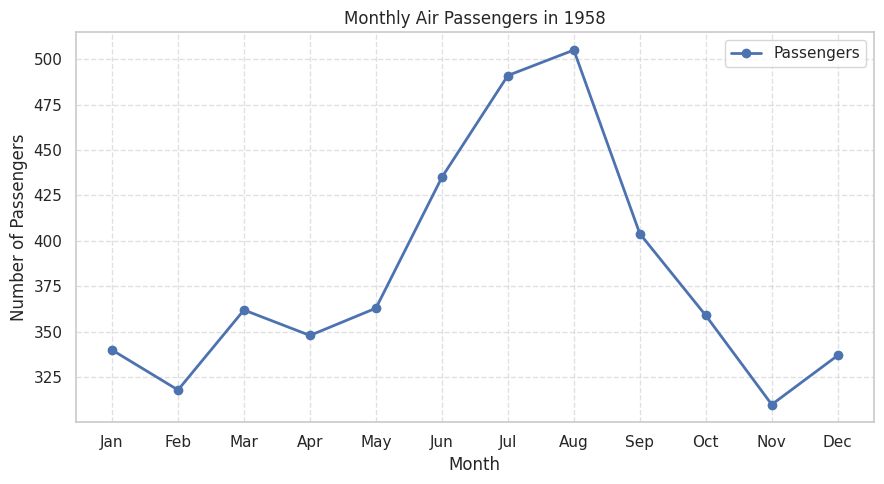

In [9]:
year_data = flights[flights["year"] == 1958]

plt.figure(figsize=(9, 5))
plt.plot(year_data["month"], year_data["passengers"], marker="o", linewidth=2, label="Passengers")
plt.title("Monthly Air Passengers in 1958")
plt.xlabel("Month")
plt.ylabel("Number of Passengers")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

**Task 2: Bar Chart**

The bar heights compare the average bill for each day. The tallest bar represents the day with the highest average total bill in this dataset.

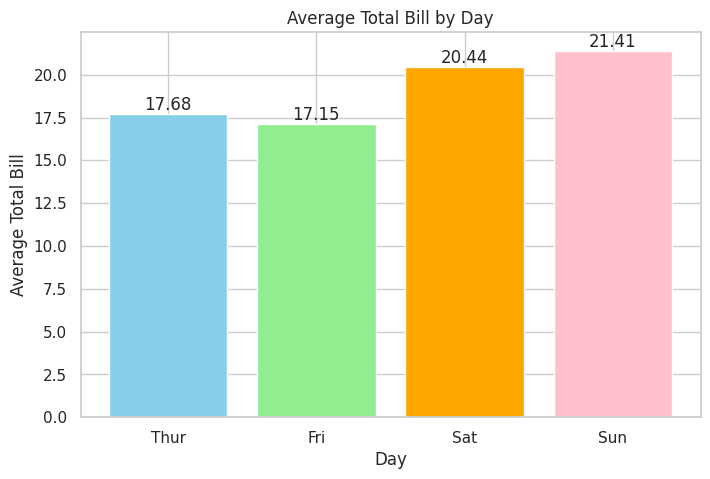

In [11]:
avg_bill = tips.groupby("day", observed=False)["total_bill"].mean().reindex(["Thur", "Fri", "Sat", "Sun"])

colors = ["skyblue", "lightgreen", "orange", "pink"]

plt.figure(figsize=(8, 5))
bars = plt.bar(avg_bill.index, avg_bill.values, color=colors)

plt.bar_label(bars, fmt="%.2f")
plt.title("Average Total Bill by Day")
plt.xlabel("Day")
plt.ylabel("Average Total Bill")
plt.show()

**Task 3: Horizontal Bar Chart**

Vehicles with fewer cylinders generally have a higher average MPG in this dataset. The horizontal bars make it easy to compare fuel efficiency across cylinder groups.


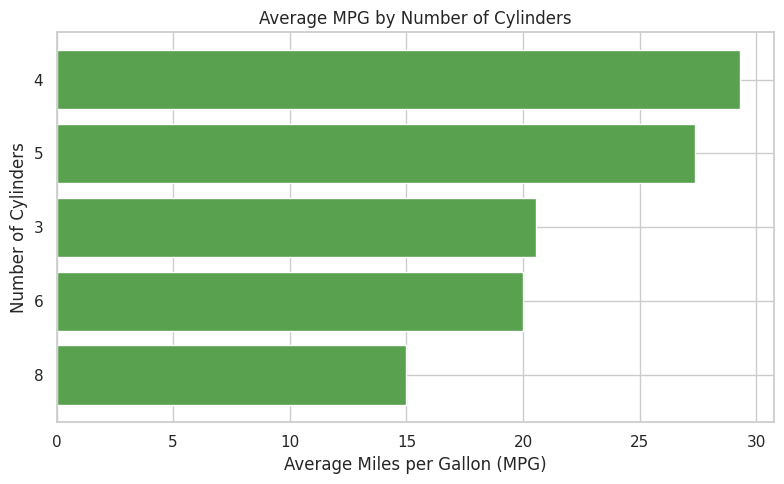

In [12]:
avg_mpg_cyl = mpg.groupby("cylinders", observed=False)["mpg"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.barh(avg_mpg_cyl.index.astype(str), avg_mpg_cyl.values, color="#59a14f")
plt.gca().invert_yaxis()
plt.title("Average MPG by Number of Cylinders")
plt.xlabel("Average Miles per Gallon (MPG)")
plt.ylabel("Number of Cylinders")
plt.tight_layout()
plt.show()

**Task 4: Histogram**

The overall distribution is easier to see when comparing all three histograms. More bins show finer detail, while fewer bins give a simpler summary of the bill amounts.

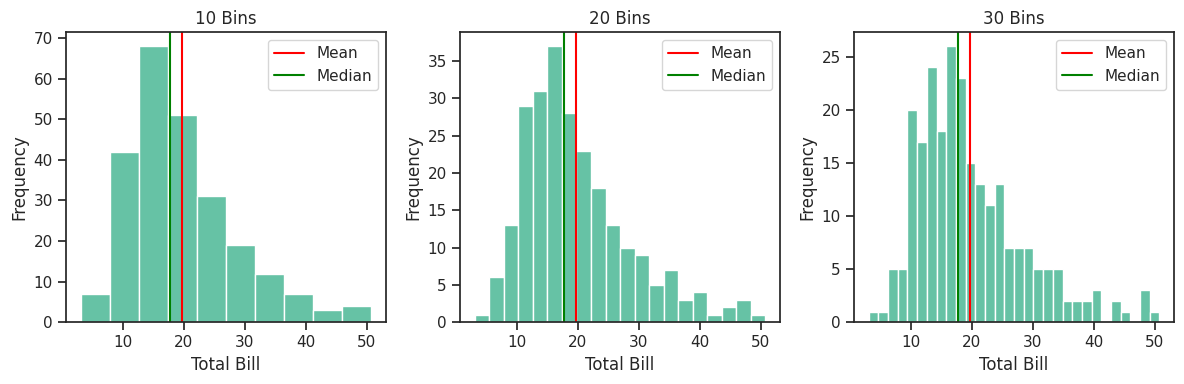

In [28]:
plt.figure(figsize=(12, 4))

for i, b in enumerate([10, 20, 30]):
    plt.subplot(1, 3, i+1)
    plt.hist(tips["total_bill"], bins=b)
    plt.axvline(tips["total_bill"].mean(), color="red", label="Mean")
    plt.axvline(tips["total_bill"].median(), color="green", label="Median")
    plt.title(f"{b} Bins")
    plt.xlabel("Total Bill")
    plt.ylabel("Frequency")
    plt.legend()

plt.tight_layout()
plt.show()

**Task 5: Scatter Plot**

The scatter plot shows a negative relationship: heavier vehicles often have lower MPG. Colors compare vehicle origins, while larger circles represent vehicles with higher horsepower.

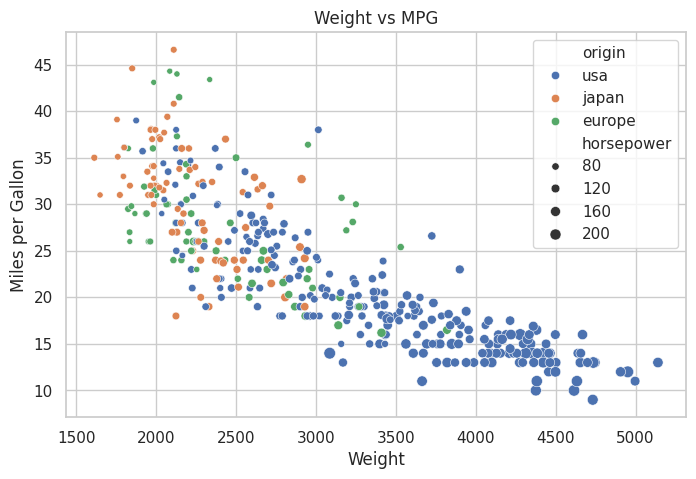

In [14]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=mpg,
    x="weight",
    y="mpg",
    hue="origin",
    size="horsepower"
)

plt.title("Weight vs MPG")
plt.xlabel("Weight")
plt.ylabel("Miles per Gallon")
plt.legend()
plt.show()

**Task 6: Pie Chart**

 The pie chart compares the proportions of smokers and non-smokers among the customers in the tips dataset. The percentage labels show which group makes up the larger share.

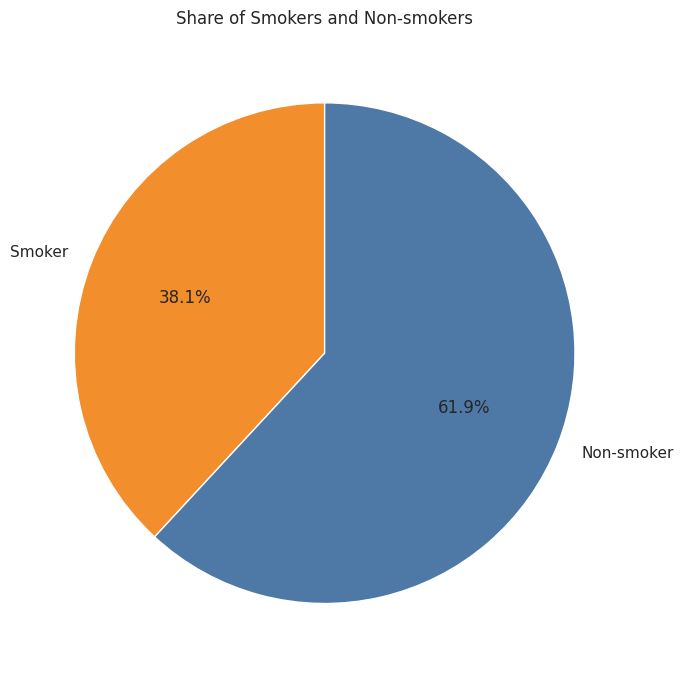

In [15]:
smoker_counts = tips["smoker"].value_counts().reindex(["Yes", "No"]).dropna()

plt.figure(figsize=(7, 7))
plt.pie(smoker_counts.values, labels=["Smoker", "Non-smoker"], autopct="%1.1f%%", startangle=90, colors=["#f28e2b", "#4e79a7"], wedgeprops={"edgecolor": "white"})
plt.title("Share of Smokers and Non-smokers")
plt.axis("equal")
plt.tight_layout()
plt.show()

**Task 7: Mini Dashboard**

The dashboard brings four views together for quick comparison. It shows monthly passenger changes, average bills by day, fuel efficiency by cylinder count, and the relationship between vehicle weight and MPG.

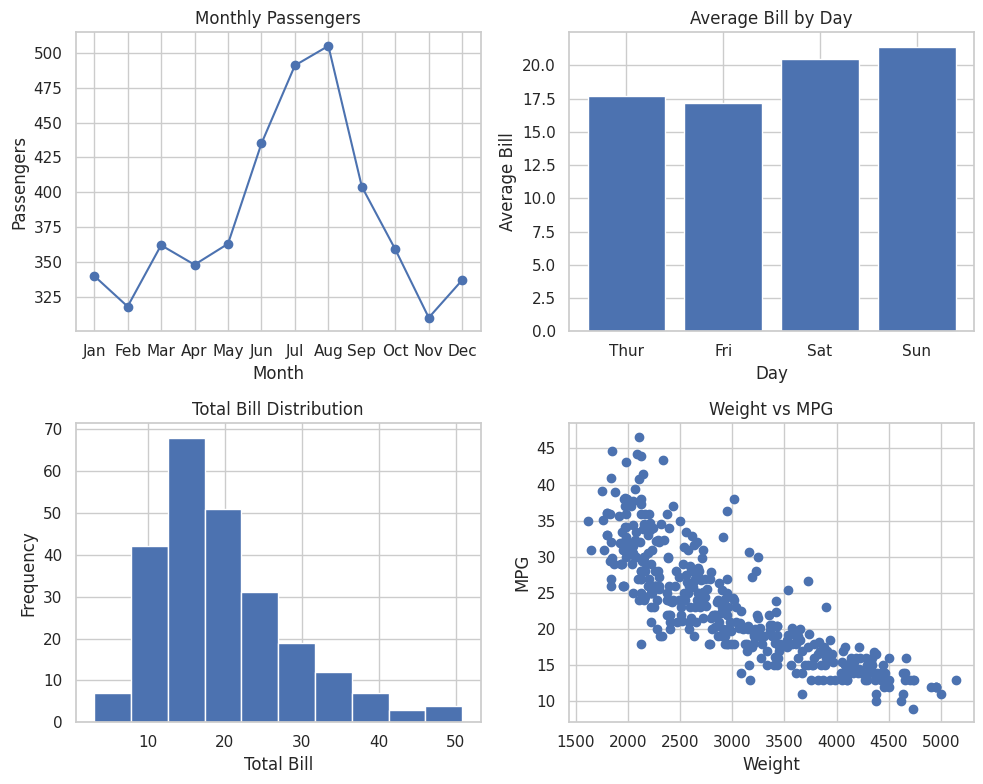

In [16]:
plt.figure(figsize=(10, 8))

# Plot 1: Line plot
plt.subplot(2, 2, 1)
plt.plot(year_data["month"], year_data["passengers"], marker="o")
plt.title("Monthly Passengers")
plt.xlabel("Month")
plt.ylabel("Passengers")

# Plot 2: Bar chart
plt.subplot(2, 2, 2)
plt.bar(avg_bill.index, avg_bill.values)
plt.title("Average Bill by Day")
plt.xlabel("Day")
plt.ylabel("Average Bill")

# Plot 3: Histogram
plt.subplot(2, 2, 3)
plt.hist(tips["total_bill"], bins=10)
plt.title("Total Bill Distribution")
plt.xlabel("Total Bill")
plt.ylabel("Frequency")

# Plot 4: Scatter plot
plt.subplot(2, 2, 4)
plt.scatter(mpg["weight"], mpg["mpg"])
plt.title("Weight vs MPG")
plt.xlabel("Weight")
plt.ylabel("MPG")

plt.tight_layout()
plt.savefig("matplotlib_mini_dashboard.png", dpi=300)
plt.show()

# SEABORN TASKS

**Task 1: Count plot**

The countplot compares passenger numbers across the three classes and separates each class by gender. It makes it easy to see which class and gender groups had more passengers.

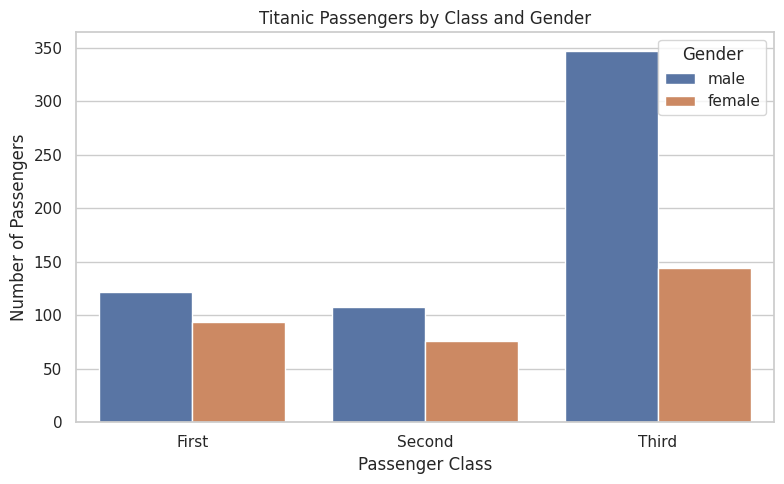

In [19]:
plt.figure(figsize=(8, 5))
sns.countplot(data=titanic, x="class", hue="sex", order=["First", "Second", "Third"])
plt.title("Titanic Passengers by Class and Gender")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

**Task 2: Histogram with KDE**

The distributions show how flipper lengths vary across penguin species. Peaks and overlaps help us compare typical flipper lengths and see how distinct the groups are.

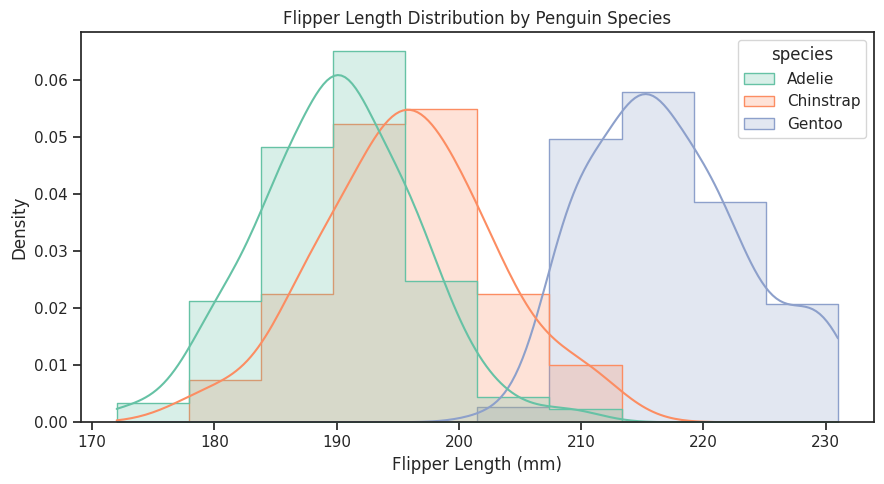

In [27]:
penguin_flippers = penguins.dropna(subset=["flipper_length_mm", "species"])

plt.figure(figsize=(9, 5))
sns.histplot(data=penguin_flippers, x="flipper_length_mm", hue="species", kde=True, element="step", common_norm=False)
plt.title("Flipper Length Distribution by Penguin Species")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

**Task 3: Box Plot vs Violin**

*   The box plot clearly shows the median, spread, and possible outliers for each species
*   The violin plot also shows the shape and density of the body-mass distribution, so it gives more detail about where values are concentrated.

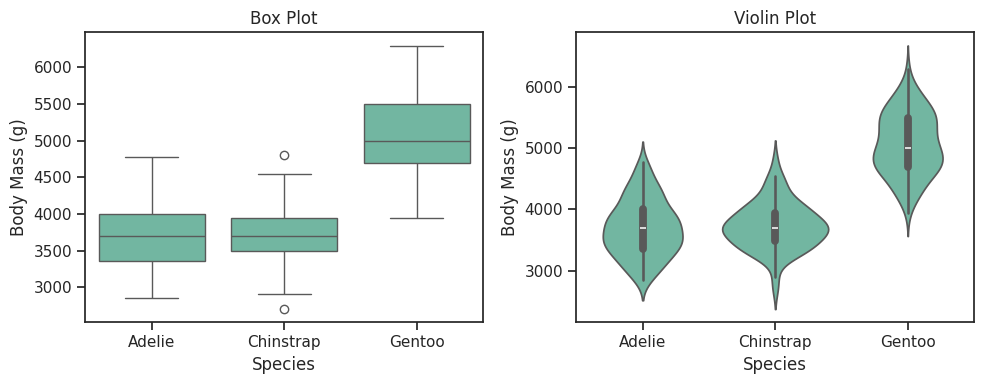

In [30]:
plt.figure(figsize=(10, 4))

# Box Plot
plt.subplot(1, 2, 1)
sns.boxplot(data=penguins, x="species", y="body_mass_g")
plt.title("Box Plot")
plt.xlabel("Species")
plt.ylabel("Body Mass (g)")

# Violin Plot
plt.subplot(1, 2, 2)
sns.violinplot(data=penguins, x="species", y="body_mass_g")
plt.title("Violin Plot")
plt.xlabel("Species")
plt.ylabel("Body Mass (g)")

plt.tight_layout()
plt.show()

**Task 4: Scatter Plot**

The points form groups by species, showing that bill dimensions differ among penguin species.

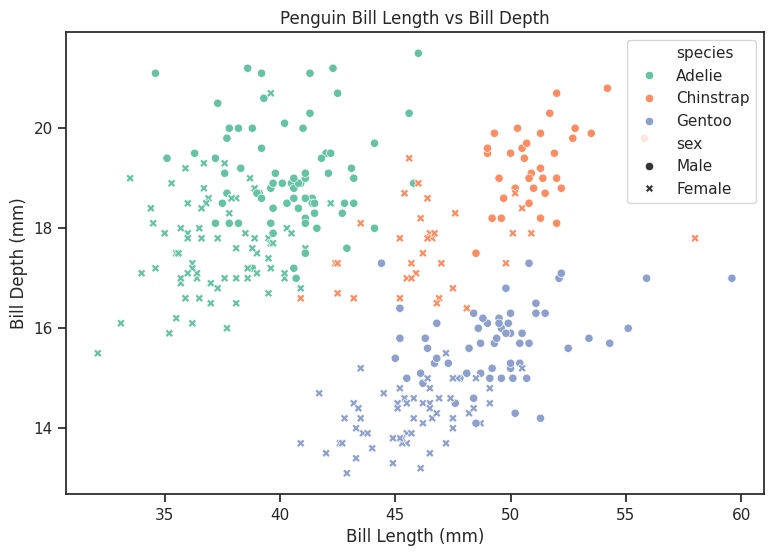

In [31]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=penguins,
    x="bill_length_mm",
    y="bill_depth_mm",
    hue="species",
    style="sex"
)

plt.title("Penguin Bill Length vs Bill Depth")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.show()

**Task 5: Heatmap**

 The heatmap shows the direction and strength of relationships between numeric features. Values near 1 indicate a strong positive relationship, values near -1 a strong negative relationship, and values near 0 a weak linear relationship.



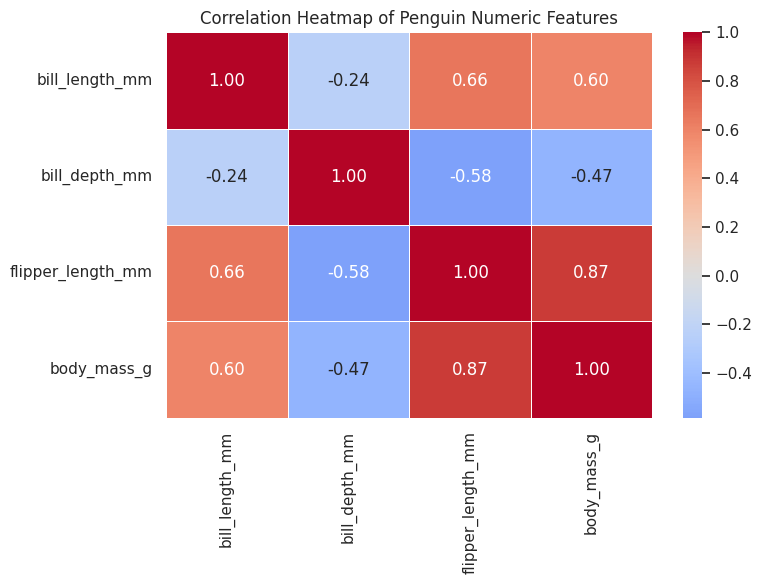

In [23]:
numeric_penguins = penguins.select_dtypes(include="number")
correlation = numeric_penguins.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", center=0, fmt=".2f",
            linewidths=0.5)
plt.title("Correlation Heatmap of Penguin Numeric Features")
plt.tight_layout()
plt.show()

**Task 6: Pair Plot**

  

*   Penguin species form distinguishable groups across several numeric measurements.
*   Flipper length and body mass tend to increase together.
*    The diagonal histograms show how the distribution of each measurement differs by species.

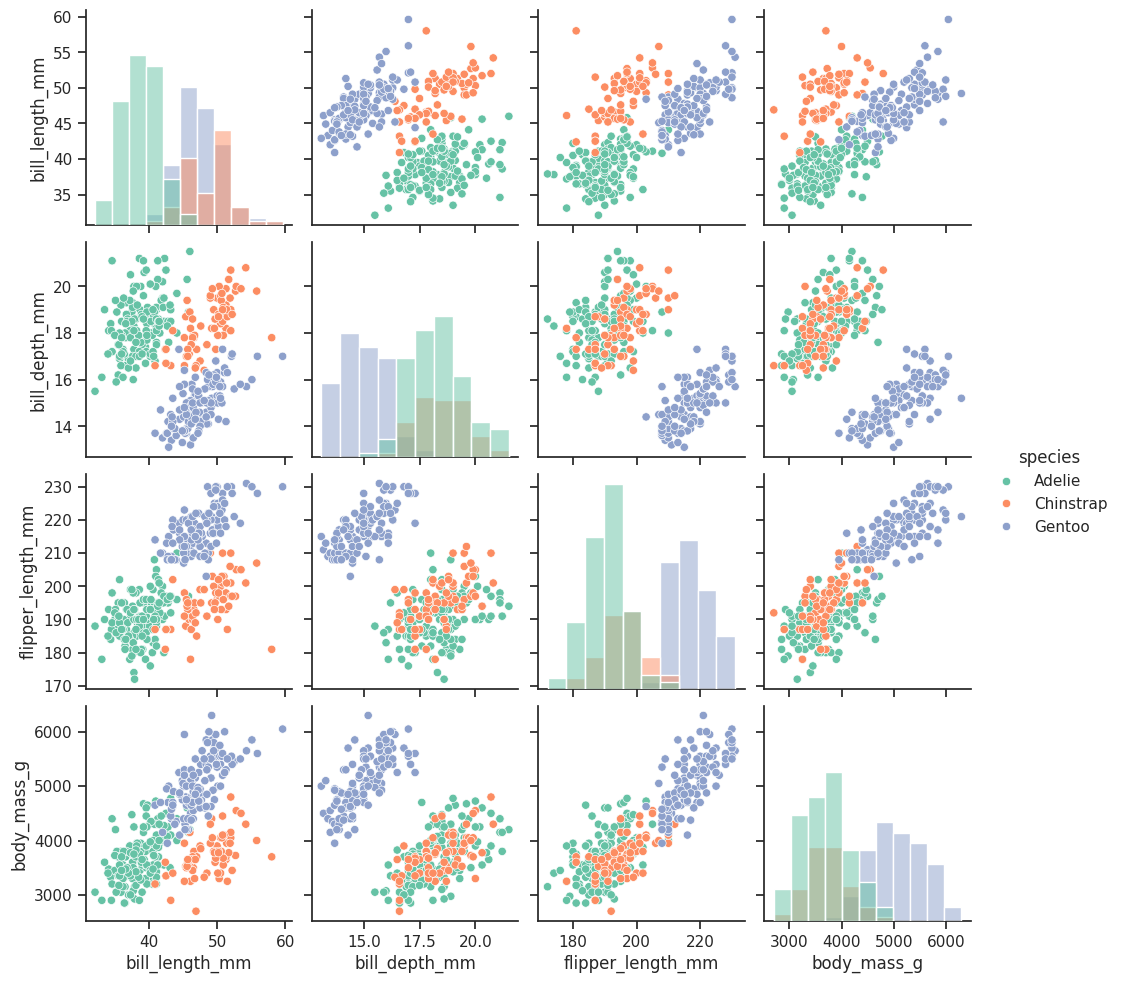

In [33]:
pairplot_data = penguins.dropna(subset=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "species"])
sns.pairplot(pairplot_data,
             vars=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"],
            hue="species", diag_kind="hist")
plt.show()

**Task 7: LmPlot**

The regression lines show the general relationship between the total bill and tip for each time/smoker group.

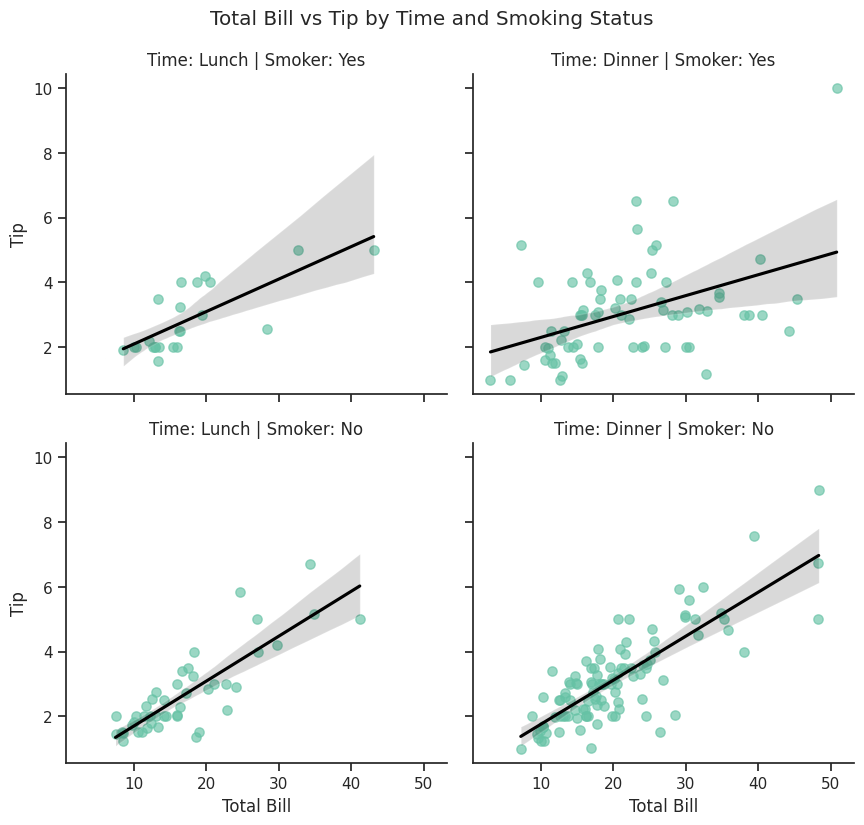

In [25]:
sns.set_theme(style="ticks", palette="Set2", context="notebook")

tips_clean = tips.dropna(subset=["total_bill", "tip", "time", "smoker"])
g = sns.lmplot(data=tips_clean, x="total_bill", y="tip",
               col="time", row="smoker", height=4, aspect=1.1,
               markers=["o"], scatter_kws={"alpha": 0.65, "s": 45},
               line_kws={"color": "black"})
g.set_axis_labels("Total Bill", "Tip")
g.set_titles("Time: {col_name} | Smoker: {row_name}")
g.fig.suptitle("Total Bill vs Tip by Time and Smoking Status", y=1.03)
plt.show()